Univariate Theta (Normal Eq): [4.22215108 2.96846751]
Sklearn Intercept: 4.2222, Slope: 2.9685


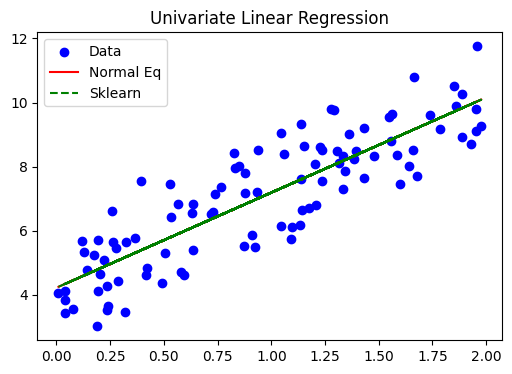


Multivariate Theta (Normal Eq): [4.91894499 2.12052741 2.88051226]
Sklearn Intercept: 4.9189, Coefs: [2.12052741 2.88051226]


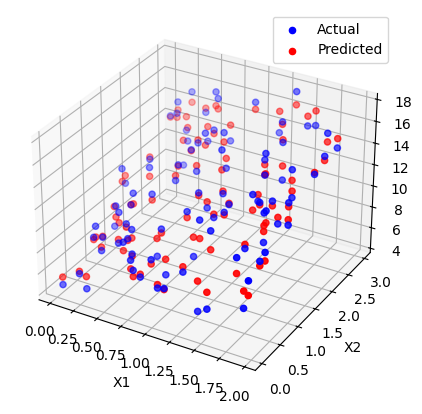

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# -----------------------------
# 1. Univariate Linear Regression
# -----------------------------

np.random.seed(0)

x = 2 * np.random.rand(100, 1)
y = 4 + 3 * x + np.random.randn(100, 1)

# Normal Equation
X = np.c_[np.ones((100, 1)), x]

theta = (
    np.linalg.inv(X.T.dot(X))
    .dot(X.T)
    .dot(y)
)

# Sklearn
model = LinearRegression().fit(x, y)

print(
    "Univariate Theta (Normal Eq):",
    theta.ravel()
)

print(
    f"Sklearn Intercept: {model.intercept_[0]:.4f}, "
    f"Slope: {model.coef_[0][0]:.4f}"
)

plt.figure(figsize=(6, 4))

plt.scatter(
    x, y,
    color="blue",
    label="Data"
)

plt.plot(
    x,
    X.dot(theta),
    "r-",
    label="Normal Eq"
)

plt.plot(
    x,
    model.predict(x),
    "g--",
    label="Sklearn"
)

plt.title("Univariate Linear Regression")
plt.legend()
plt.show()


# -----------------------------
# 2. Multivariate Linear Regression
# -----------------------------

x1 = 2 * np.random.rand(100, 1)
x2 = 3 * np.random.rand(100, 1)

y_multi = (
    5 + 2 * x1 + 3 * x2
    + np.random.randn(100, 1)
)

# Normal Equation
X_multi = np.c_[
    np.ones((100, 1)),
    x1,
    x2
]

theta_multi = (
    np.linalg.inv(X_multi.T.dot(X_multi))
    .dot(X_multi.T)
    .dot(y_multi)
)

# Sklearn
X_sk = np.c_[x1, x2]

model_multi = LinearRegression().fit(
    X_sk,
    y_multi
)

print(
    "\nMultivariate Theta (Normal Eq):",
    theta_multi.ravel()
)

print(
    f"Sklearn Intercept: {model_multi.intercept_[0]:.4f}, "
    f"Coefs: {model_multi.coef_.ravel()}"
)

# 3D Visualization
fig = plt.figure(figsize=(7, 5))

ax = fig.add_subplot(
    projection='3d'
)

ax.scatter(
    x1,
    x2,
    y_multi,
    color='blue',
    label='Actual'
)

ax.scatter(
    x1,
    x2,
    X_multi.dot(theta_multi),
    color='red',
    label='Predicted'
)

ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_zlabel("Y")

plt.legend()
plt.show()